# 07b. Error analysis of the headline model

Headline model (chosen in task 3.4.5): **LightGBM on the `forecast` feature set** (`lgbm_forecast_weather`). Persistence and ridge with forecast weather are shown for context. Same walk-forward protocol as notebooks 06 and 07. Errors are forecast minus observed (ug/m3), so negative means too low.

Two test views, as before: `observed` (perfect-forecast weather, upper bound, all winters 2020-21 to 2024-25) and `forecast` (real archived forecasts, from 2024, small sample). There is one station and the target is a daily mean, so analysis by hour or station does not apply.

In [1]:
import warnings
from datetime import date
from pathlib import Path

import pandas as pd

from aeron.evaluation import errors, report, splits
from aeron.evaluation.runner import common_rows, run_models
from aeron.models import baselines, trees

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
daily = pd.read_csv(
    ROOT / "data" / "processed" / "daily_us_embassy.csv", index_col=0, parse_dates=True
)
blocks = splits.seasonal_blocks(2020, date(2025, 2, 25))
LEADS, VIEWS = (1, 2, 3), ("observed", "forecast")
HEAD = "lgbm_forecast_weather"
NAMES = ["persistence", "ridge_forecast_weather", HEAD]

preds = {}
for view in VIEWS:
    for lead in LEADS:
        models = [m for m in baselines.default_models() if m.name in NAMES[:2]]
        models.append(trees.lightgbm_model("forecast", HEAD))
        preds[(view, lead)] = common_rows(
            run_models(daily, models, lead, blocks, view), NAMES
        )
print({k: len(v) for k, v in preds.items()})

{('observed', 1): 1172, ('observed', 2): 1144, ('observed', 3): 1129, ('forecast', 1): 363, ('forecast', 2): 358, ('forecast', 3): 354}


## 4.1.1 Error structure

### By season and lead

In [2]:
rows = []
for (view, lead), p in preds.items():
    s = report.summarize(p, NAMES)
    s = s[s["model"] == HEAD][["group", "n", "mae", "rmse", "bias"]]
    s.insert(0, "lead", lead)
    s.insert(0, "view", view)
    rows.append(s)
pd.concat(rows).round(1).set_index(["view", "lead", "group"])

n   mae  rmse  bias
view     lead group                         
observed 1    winter   467  15.5  22.5  -5.4
              other    705   6.1   9.2   0.1
              all     1172   9.8  15.9  -2.1
         2    winter   456  18.6  29.9  -7.2
              other    688   7.9  11.4   2.0
              all     1144  12.2  20.9  -1.7
         3    winter   446  19.2  31.0  -8.5
              other    683   8.0  12.0   1.7
              all     1129  12.4  21.6  -2.3
forecast 1    winter   146  17.1  22.8   2.9
              other    217   9.9  13.7   5.5
              all      363  12.8  17.9   4.5
         2    winter   143  20.9  26.4   2.6
              other    215  11.8  16.8   6.8
              all      358  15.5  21.2   5.1
         3    winter   140  22.0  28.1   5.1
              other    214  12.5  18.0   8.2
              all      354  16.3  22.5   7.0

### By pollution level (observed daily mean), winter only

In [3]:
def winter(p):
    return p[p["season"] == "winter"]


for view in VIEWS:
    for lead in LEADS:
        print(view, "lead", lead)
        print(
            errors.error_by_level(winter(preds[(view, lead)]), HEAD)
            .round(2)
            .to_string()
        )
        print()

observed lead 1
          days    mae   bias  share_of_days  share_of_abs_error
level                                                          
<25         58  10.74  10.52           0.12                0.09
25-55.5    199   9.21   3.11           0.43                0.25
55.5-100   152  15.77  -9.28           0.33                0.33
>=100       58  40.88 -40.55           0.12                0.33

observed lead 2
          days    mae   bias  share_of_days  share_of_abs_error
level                                                          
<25         59  13.06  13.04           0.13                0.09
25-55.5    191  10.27   4.30           0.42                0.23
55.5-100   149  18.12 -12.20           0.33                0.32
>=100       57  53.75 -53.75           0.12                0.36

observed lead 3
          days    mae   bias  share_of_days  share_of_abs_error
level                                                          
<25         57  13.64  13.64           0.13           

### By month and weekday, observed view, lead 1 (all rows)

In [4]:
print(errors.error_by_month(preds[("observed", 1)], HEAD).round(1).to_string())
print()
print(errors.error_by_weekday(preds[("observed", 1)], HEAD).round(1).to_string())

       days   mae  bias
month                  
1       137  17.0  -6.1
2       100  10.9  -2.1
3        91   8.3   0.0
4        96   5.4  -0.8
5        99   4.3   0.4
6       108   5.1   1.4
7        75   5.8   2.0
8        80   4.6   1.5
9        71   8.4  -4.4
10       85   7.7   0.2
11      110  12.9  -2.8
12      120  19.9  -9.8

           days   mae  bias
weekday                    
Monday      169   7.9  -2.4
Tuesday     167   9.9  -1.1
Wednesday   170  11.0  -1.7
Thursday    164  10.3  -1.4
Friday      168  10.6  -2.8
Saturday    168   9.3  -2.6
Sunday      166   9.7  -2.5


### Do errors repeat from day to day?

Correlation of the error with the error k days earlier, winter days, headline model (pairs of consecutive days only).

In [5]:
rows = []
for (view, lead), p in preds.items():
    ac = errors.error_autocorrelation(winter(p), HEAD, 3)
    rows.append(
        {"view": view, "lead": lead, **{f"lag {k}": round(v, 2) for k, v in ac.items()}}
    )
pd.DataFrame(rows).set_index(["view", "lead"])

lag 1  lag 2  lag 3
view     lead                     
observed 1      0.25   0.13   0.19
         2      0.38   0.14   0.16
         3      0.52   0.23   0.18
forecast 1      0.12  -0.20  -0.12
         2      0.28  -0.23  -0.16
         3      0.32  -0.11  -0.14

## 4.1.2 Extreme events (RQ7)

### Days with an observed daily mean at or above 100 ug/m3 (winter)

In [6]:
rows = []
for (view, lead), p in preds.items():
    for name in NAMES:
        t = errors.tail_performance(winter(p), name, 100.0)
        rows.append({"view": view, "lead": lead, "model": name, **t})
pd.DataFrame(rows).round(2).set_index(["view", "lead", "model"])

days  mean_error    mae  share_forecast_at_alert  share_forecast_at_threshold
view     lead model                                                                                                
observed 1    persistence               58      -15.15  39.43                     0.86                         0.55
              ridge_forecast_weather    58      -32.92  36.01                     0.97                         0.40
              lgbm_forecast_weather     58      -40.55  40.88                     0.93                         0.31
         2    persistence               57      -38.38  55.99                     0.65                         0.35
              ridge_forecast_weather    57      -53.79  54.83                     0.91                         0.07
              lgbm_forecast_weather     57      -53.75  53.75                     0.84                         0.05
         3    persistence               55      -43.70  58.09                     0.67                         0.31
              ridge_forecast_weather    55      -59.34  59.34                     0.93                         0.02
              lgbm_forecast_weather     55      -58.73  58.73                     0.80                         0.04
forecast 1    persistence               17      -26.92  34.63                     0.82                         0.29
              ridge_forecast_weather    17      -27.23  30.00                     1.00                         0.18
              lgbm_forecast_weather     17      -24.00  28.05                     1.00                         0.24
         2    persistence               16      -53.21  53.24                     0.50                         0.12
              ridge_forecast_weather    16      -45.08  45.08                     0.94                         0.00
              lgbm_forecast_weather     16      -34.47  34.47                     0.94                         0.00
         3    persistence               16      -55.55  56.08                     0.50                         0.06
              ridge_forecast_weather    16      -46.58  46.58                     0.88                         0.00
              lgbm_forecast_weather     16      -30.58  32.26                     0.94                         0.25

### Episodes of two or more consecutive days at or above 100 ug/m3, observed view, headline model

In [7]:
for lead in LEADS:
    ep = errors.find_episodes(preds[("observed", lead)], HEAD, 100.0, 2)
    print(
        f"lead {lead}: {len(ep)} episodes, {int((ep['days_alerted'] / ep['days'] >= 0.5).sum())} with the alert level (55.5) forecast on at least half of their days, "
        f"{int((ep['days_alerted'] == 0).sum())} never alerted"
    )
ep1 = errors.find_episodes(preds[("observed", 1)], HEAD, 100.0, 2)
ep1.round(1)

lead 1: 18 episodes, 17 with the alert level (55.5) forecast on at least half of their days, 1 never alerted
lead 2: 17 episodes, 14 with the alert level (55.5) forecast on at least half of their days, 2 never alerted
lead 3: 18 episodes, 14 with the alert level (55.5) forecast on at least half of their days, 4 never alerted


,start,end,days,peak_observed,mean_observed,mean_forecast,mean_error,days_alerted
0,2021-11-07,2021-11-09,3,207.5,142.8,92.9,-49.9,3
1,2021-12-08,2021-12-09,2,124.4,119.1,74.9,-44.2,2
2,2022-12-10,2022-12-13,4,181.5,136.6,96.3,-40.3,4
3,2022-12-17,2022-12-19,3,106.2,103.1,92.6,-10.5,3
4,2023-01-17,2023-01-21,5,155.7,139.8,98.4,-41.4,5
5,2023-01-24,2023-01-27,4,174.9,162.1,108.8,-53.3,4
6,2023-01-29,2023-01-30,2,183.8,142.3,96.2,-46.1,2
7,2023-12-02,2023-12-04,3,141.5,125.9,81.2,-44.7,3
8,2023-12-13,2023-12-14,2,214.2,169.6,106.4,-63.2,2
9,2023-12-22,2023-12-23,2,220.3,183.5,96.8,-86.7,2


In [8]:
ep3 = errors.find_episodes(preds[("observed", 3)], HEAD, 100.0, 2)
ep3.round(1)

,start,end,days,peak_observed,mean_observed,mean_forecast,mean_error,days_alerted
0,2021-11-06,2021-11-07,2,378.7,293.1,68.7,-224.3,2
1,2021-12-08,2021-12-09,2,124.4,119.1,53.7,-65.4,1
2,2022-12-11,2022-12-13,3,181.5,144.4,77.5,-66.9,3
3,2022-12-17,2022-12-19,3,106.2,103.1,81.6,-21.5,3
4,2023-01-19,2023-01-21,3,155.7,139.0,81.4,-57.6,3
5,2023-01-23,2023-01-24,2,162.5,161.3,84.4,-76.8,2
6,2023-01-26,2023-01-27,2,174.9,165.9,83.9,-82.0,2
7,2023-01-29,2023-01-30,2,183.8,142.3,82.3,-60.0,2
8,2023-12-02,2023-12-04,3,141.5,125.9,45.9,-80.0,0
9,2023-12-13,2023-12-14,2,214.2,169.6,79.7,-90.0,2


### False alarms: runs of two or more days with the forecast at or above 55.5 while the observed mean stayed below it

In [9]:
for view in VIEWS:
    for lead in LEADS:
        fa = errors.false_alarm_runs(winter(preds[(view, lead)]), HEAD)
        total_alerts = int((winter(preds[(view, lead)])[HEAD] >= 55.5).sum())
        print(
            f"{view} lead {lead}: {len(fa)} runs, {int(fa['days'].sum()) if len(fa) else 0} days (of {total_alerts} alert days)"
        )
errors.false_alarm_runs(winter(preds[("observed", 1)]), HEAD).round(1)

observed lead 1: 3 runs, 8 days (of 197 alert days)
observed lead 2: 6 runs, 14 days (of 172 alert days)
observed lead 3: 4 runs, 9 days (of 159 alert days)
forecast lead 1: 1 runs, 2 days (of 76 alert days)
forecast lead 2: 5 runs, 11 days (of 76 alert days)
forecast lead 3: 3 runs, 8 days (of 72 alert days)


,start,end,days,mean_forecast,mean_observed
0,2020-12-14,2020-12-15,2,75.1,53.8
1,2021-01-05,2021-01-08,4,72.9,46.5
2,2025-02-22,2025-02-23,2,56.7,40.7


## 4.1.3 Temporal stability (RQ5)

### MAE per test block, headline model against persistence (observed view)

In [10]:
for lead in (1, 3):
    t = report.per_block_mae(preds[("observed", lead)], NAMES)
    t["skill_vs_persistence"] = 1 - t[HEAD] / t["persistence"]
    print("lead", lead)
    print(t.round(2).to_string())
    print()

lead 1
                days  persistence  ridge_forecast_weather  lgbm_forecast_weather  skill_vs_persistence
block                                                                                                 
winter 2020-21    88        13.92                   10.87                  12.55                  0.10
mar-oct 2021     176         7.25                    6.45                   5.55                  0.23
winter 2021-22   102        18.04                   11.20                  11.43                  0.37
mar-oct 2022     104         5.82                    6.12                   4.64                  0.20
winter 2022-23    76        21.41                   18.08                  16.55                  0.23
mar-oct 2023     208         6.80                    6.48                   5.52                  0.19
winter 2023-24    93        28.92                   20.50                  22.30                  0.23
mar-oct 2024     217         8.50                    7.83         

### Rolling 28-day MAE (observed view, lead 1) and the same on real forecasts

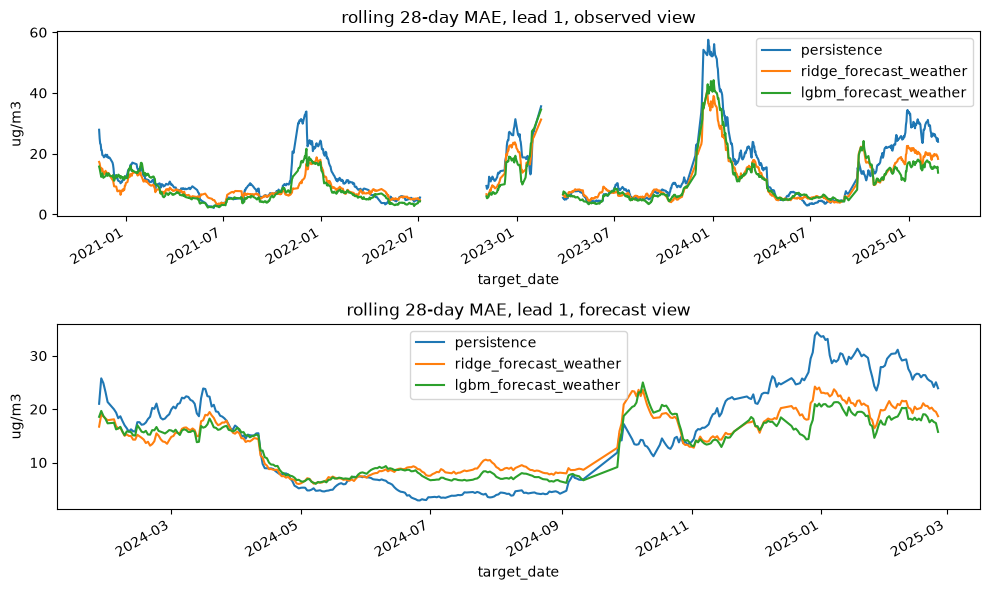

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=False)
for ax, view in zip(axes, VIEWS):
    for name in NAMES:
        errors.rolling_mae(preds[(view, 1)], name, 28).plot(ax=ax, label=name)
    ax.set_title(f"rolling 28-day MAE, lead 1, {view} view")
    ax.set_ylabel("ug/m3")
    ax.legend()
fig.tight_layout()
(ROOT / "reports" / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(ROOT / "reports" / "figures" / "07b_rolling_mae.png", dpi=120)
plt.show()

### Does the error grow with time? Winter MAE by winter, headline model

In [12]:
rows = {}
for lead in LEADS:
    q = winter(preds[("observed", lead)]).copy()
    d = pd.DatetimeIndex(q["target_date"])
    q["winter starting"] = [y if m >= 11 else y - 1 for y, m in zip(d.year, d.month)]
    g = q.groupby("winter starting")
    rows[f"lead {lead} MAE"] = g.apply(lambda x: (x[HEAD] - x["y"]).abs().mean())
    rows[f"lead {lead} mean observed"] = g["y"].mean()
pd.DataFrame(rows).round(1)

,lead 1 MAE,lead 1 mean observed,lead 2 MAE,lead 2 mean observed,lead 3 MAE,lead 3 mean observed
winter starting,,,,,,
2020,12.6,53.7,13.8,54.1,13.8,54.8
2021,11.4,49.8,14.4,51.4,16.4,52.6
2022,16.6,66.4,21.0,64.9,22.6,63.5
2023,22.3,67.4,25.6,65.7,25.7,64.3
2024,15.0,61.2,19.0,61.6,18.4,62.2


## Saved tables

In [13]:
out = []
for (view, lead), p in preds.items():
    lv = errors.error_by_level(winter(p), HEAD).reset_index()
    lv.insert(0, "lead", lead)
    lv.insert(0, "view", view)
    out.append(lv)
target = ROOT / "reports" / "model_evaluation"
pd.concat(out).round(4).to_csv(target / "error_by_level.csv", index=False)
ep = []
for lead in LEADS:
    e = errors.find_episodes(preds[("observed", lead)], HEAD, 100.0, 2)
    e.insert(0, "lead", lead)
    ep.append(e)
pd.concat(ep).round(2).to_csv(target / "episodes_observed_view.csv", index=False)
print("saved error_by_level.csv and episodes_observed_view.csv")

saved error_by_level.csv and episodes_observed_view.csv
